# Analyzing Model Outputs By Parameter

To assess the model, we ran a large parameter sweep with 5 runs for each combination of the following parameters:

* Cost functions: cost_funcs = ["raam", "gravity"]
* Transportation Options: noveh = ['onlycars', 'noveh']
* Time Steps: timesteps = [10, 15, 20, 25, 30]
* Rationality: topK = [1, 2, 3, 4, 5]
* Ratio of People to Agents: numAgents = [1000, 100, 10, 1]

In [1]:
from collections import Counter
import itertools
import json
import geopandas as gpd
from glob import glob
import math
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib.cm as cm
import numpy as np
import pandas as pd
from scipy.stats import kendalltau
import seaborn as sns
import os

Below just lists the varous accessibility fields calculated by the Pysal `access` package and a dictionary that maps the column name to a more "human readable" version of the name.

In [2]:
acc_cols = ['gravity_BEDS', '2sfca_30_BEDS', '2sfca_60_BEDS', 'e2sfca_30_BEDS', 'e2sfca_60_BEDS',
            'g2sfca10_BEDS', 'g2sfca20_BEDS', '3sfca_BEDS', 'raam30_BEDS', 'raam60_BEDS']
acc_titles = {
    'gravity_BEDS': "Gravity",
    '2sfca_30_BEDS': "2SFCA (30min)",
    '2sfca_60_BEDS': "2SFCA (60min)",
    'e2sfca_30_BEDS': "E2SFCA (30min)",
    'e2sfca_60_BEDS': "E2SFCA (60 min)",
    'g2sfca10_BEDS': r"G2SFCA ($\sigma$=10)",
    'g2sfca20_BEDS': r"G2SFCA ($\sigma$=20)",
    '3sfca_BEDS': "3SFCA",
    'raam30_BEDS': r"RAAM ($\tau$=30)",
    'raam60_BEDS': r"RAAM ($\tau$=60)"
}

The next code block allows us to compare a given spatial accessibility method to our model outputs.

* `acc_corr` is the traditional accessibility method column we will calculate correlations against.
* `Cost_2` is the AgentAccess model output we will use. we have 2, 3, and 4 corresponding to the average of the last 1/2, 1/3, and 1/4 timesteps of the model.

In [3]:
acc_corr = "raam30_BEDS"
# acc_corr = "gravity_BEDS"
res_col = "Cost_2"

Loading the hospital data to aid in analysis.

In [4]:
# load the hospitals
hos = gpd.read_file("../data/hospitals/ContinentalHospitals.shp")
hos = hos[(hos["STATE"] == "IL") & (hos["COUNTY"] == "COOK")]
hos = hos[hos["BEDS"] >= 0]
hos = hos.to_crs("EPSG:4326")
print(len(hos), sum(hos["BEDS"]))
hos.head()

66 18259


,OBJECTID,ID,NAME,ADDRESS,CITY,STATE,ZIP,ZIP4,TELEPHONE,TYPE,...,WEBSITE,STATE_ID,ALT_NAME,ST_FIPS,OWNER,TTL_STAFF,BEDS,TRAUMA,HELIPAD,geometry
507,1513,0003460644,UHS HARTGROVE HOSPITAL,5730 WEST ROOSEVELT ROAD,CHICAGO,IL,60644,NOT AVAILABLE,(773) 413-1700,PSYCHIATRIC,...,http://www.hartgrovehospital.com,0005454,NOT AVAILABLE,17,PROPRIETARY,-999,128,NOT AVAILABLE,N,POINT (-87.76746 41.86633)
508,1514,0001860612,JESSE BROWN VA MEDICAL CENTER - VA CHICAGO HEA...,820 S DAMEN STREET,CHICAGO,IL,60612,NOT AVAILABLE,(312) 569-8387,MILITARY,...,http://www.chicago.va.gov/,14003F,NOT AVAILABLE,17,GOVERNMENT - FEDERAL,-999,240,NOT AVAILABLE,N,POINT (-87.67704 41.87074)
509,1515,0003160463,PALOS COMMUNITY HOSPITAL,12251 SOUTH 80TH AVENUE,PALOS HEIGHTS,IL,60464,NOT AVAILABLE,(708) 923-4000,GENERAL ACUTE CARE,...,http://www.paloscommunityhospital.org,140062,NOT AVAILABLE,17,NON-PROFIT,-999,377,NOT AVAILABLE,Y,POINT (-87.81344 41.66921)
510,1516,0003660628,ROSELAND COMMUNITY HOSPITAL,45 W 111TH STREET,CHICAGO,IL,60628,NOT AVAILABLE,(773) 995-3000,GENERAL ACUTE CARE,...,http://www.roselandhospital.org,140068,NOT AVAILABLE,17,NON-PROFIT,-999,115,NOT AVAILABLE,N,POINT (-87.62536 41.69223)
511,1517,0002360302,WEST SUBURBAN MEDICAL CENTER,3 ERIE COURT,OAK PARK,IL,60302,NOT AVAILABLE,(708) 383-6200,GENERAL ACUTE CARE,...,http://www.westsuburbanmc.com/Home.aspx,140049,NOT AVAILABLE,17,PROPRIETARY,-999,172,NOT AVAILABLE,N,POINT (-87.77618 41.8914)


Load our analysis of accessibility to hospital beds in Cook County.

In [5]:
acc = gpd.read_file("../data/accessibility/CookHospitals.gpkg")
acc = acc.set_index("geoid")
cols = list(acc.columns)
cols.remove('geometry')
# acc = normalize_columns(acc, cols)
# drop rows with nan values
acc = acc.dropna(subset=[acc_corr])
print(len(acc))
acc.head()

1315


,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry
geoid,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019..."
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019..."
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012..."
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.6634 42.0150..."
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009..."


## AgentAccess Experimental Results

For each set of parameters, we ran the model 5 times resulting in ($2\cdot 2 \cdot 5 \cdot 5 \cdot 4 \cdot 5$) 2000 runs of the model.

The next few lines will collect all of the experiment outputs, in two categories: "NoVeh" meaning models that included the Census "No Vehicles" data and "Only Cars" which assumes everyone is using the driving-time data.

In [6]:
experiment_paths_nv = glob("../outputs/NoVeh/*")
experiment_paths_oc = glob("../outputs/OnlyCars/*")
# print(len(experiment_paths))
experiment_paths = {'noveh': experiment_paths_nv, 'onlycars': experiment_paths_oc}
# experiment_paths = {'onlycars': experiment_paths_oc}

Here we spell out all of the parameters we tested which is useful for iterating and sanity checking.

In [7]:
# params tested
cost_funcs = ["raam", "gravity"]
noveh = ['onlycars', 'noveh']
timesteps = [10, 15, 20, 25, 30]
topK = [1, 2, 3, 4, 5]
numAgents = [1000, 100, 10, 1]

Below is a quick sanity check that ensures we have the appropriate number of results for each parameter choice.

In [8]:
# quick sanity check
cf_counter, ts_counter, tk_counter, na_counter = Counter(), Counter(), Counter(), Counter()
for k, v in experiment_paths.items():
    for path in v:
        # print(path)
        # load the parameter json
        param_path = os.path.join(path, "parameters.json")
        param_file = open(param_path)
        params = json.load(param_file)
        cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
    #     print(cf, ts, tk, na)
        cf_counter[cf] +=1
        ts_counter[ts] +=1
        tk_counter[tk] +=1
        na_counter[na] +=1
# you should see even numbers for all parameter options
cf_counter, ts_counter, tk_counter, na_counter

(Counter({'gravity': 1000, 'raam': 1000}),
 Counter({30: 400, 25: 400, 20: 400, 15: 400, 10: 400}),
 Counter({5: 400, 4: 400, 3: 400, 1: 400, 2: 400}),
 Counter({100: 500, 1: 500, 10: 500, 1000: 500}))

The function below calculates the Kendall's $\tau$ correlation between each model output and our spatial accessibility measure, collecting it all into a dictionary that maps the parameters to a list of correlations.

In [9]:
def calculate_corrs(acc_corr, res_col):
    experiment_corr = dict()
    _negate_corr = not ("raam" in acc_corr)
    for k, v in experiment_paths.items():
        for path in v:
            # load the parameter json
            param_path = os.path.join(path, "parameters.json")
            param_file = open(param_path)
            params = json.load(param_file)
            cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
            # load the data
            results = pd.read_csv(os.path.join(path, "spatial_units.csv"), index_col="GEOID")
            results.index = results.index.map(str)
            # join with accessibility data on GEOID
            # join the last time step's cost
            merged = pd.merge(acc[[acc_corr]], results[[res_col]], left_index=True, right_index=True)
        #     print(len(merged))
            corr_res = kendalltau(merged[acc_corr], merged[res_col])
            if _negate_corr:
                _correlation = -corr_res.correlation
            else:
                _correlation = corr_res.correlation  # negate from access to cost
            try:
                experiment_corr[k, cf, ts, tk, na].append(_correlation)
            except:
                experiment_corr[k, cf, ts, tk, na] = [_correlation]
    return experiment_corr

In [10]:
experiment_corr = calculate_corrs(acc_corr, res_col)
experiment_corr

{('noveh', 'gravity', 30, 5, 100): [np.float64(0.7302252203247194),
  np.float64(0.7326165513446595),
  np.float64(0.7317970632700624),
  np.float64(0.7305076427685071),
  np.float64(0.7326142364065957)],
 ('noveh', 'gravity', 25, 4, 1): [np.float64(0.7490086277746656),
  np.float64(0.7493211444132831),
  np.float64(0.7487053708883034),
  np.float64(0.7487447248353886),
  np.float64(0.7486081434896225)],
 ('noveh', 'raam', 25, 4, 10): [np.float64(0.7974625963887678),
  np.float64(0.7988191500941743),
  np.float64(0.7974000930610443),
  np.float64(0.7974417619461933),
  np.float64(0.7971940635733631)],
 ('noveh', 'gravity', 20, 3, 1000): [np.float64(0.6761042833303523),
  np.float64(0.6807781432812327),
  np.float64(0.6679094025843813),
  np.float64(0.6670713950052735),
  np.float64(0.6770487780603965)],
 ('noveh', 'raam', 15, 1, 10): [np.float64(0.8854232980002551),
  np.float64(0.8804554409152681),
  np.float64(0.8831338242551237),
  np.float64(0.8817911601781001),
  np.float64(0.8815

Below is a simple function to calculate the minimum and maximum correlations to help set the y-axis limits for visualizations.

In [11]:
def get_ylims(ecorr):
    corrs = {'raam': [], 'gravity': []}
    for k, v in ecorr.items():
        corrs[k[1]].extend(v)
    _min = math.floor(min([min(corrs['raam']), min(corrs['gravity'])])*10)/10.0
    _max = math.ceil(max([max(corrs['raam']), max(corrs['gravity'])])*10)/10.0
    return(_min, _max)

In [12]:
print(get_ylims(experiment_corr))

(0.6, 1.0)


The function below uses our correlation data to create boxplots of the correlations between the spatial acccessibility method and our AgentAccess outputs, broken down by parameter:

In [13]:
def parameter_boxplots(experiment_corr, save_path):
    fig, axes = plt.subplots(4, 3, figsize=(14, 12))
    ylims = get_ylims(experiment_corr)
    colors = [
        ["#6267f5", "#6cf562"],
        ["#f56462", "#f5a462"]
    ]

    fsize = 20
    for i, cf in enumerate(cost_funcs):
        for j, nv in enumerate(noveh):
            # get the ax for numAgents
            ax = axes[i*2 + j, 0]
            parameters = numAgents
            oparameters = (timesteps, topK)
            vals = dict()
            for p in parameters:
                vals[p] = list()
                for a, b in itertools.product(*oparameters):
                    vals[p].extend(experiment_corr[nv, cf, a, b, p])
            x_labels = [str(x) for x in parameters]
            data = [vals[p] for p in parameters]
            ax.boxplot(data, tick_labels=x_labels)
            # ax.set_title(f"{cf}, {nv}")
            ax.set_ylim(*ylims)

            # get the ax for topk
            ax = axes[i*2 + j, 1]
            parameters = topK
            oparameters = (timesteps, numAgents)
            vals = dict()
            for p in parameters:
                vals[p] = list()
                for a, b in itertools.product(*oparameters):
                    vals[p].extend(experiment_corr[nv, cf, a, p, b])
            x_labels = [str(x) for x in parameters]
            data = [vals[p] for p in parameters]
            ax.boxplot(data, tick_labels=x_labels)
            ax.set_yticklabels([])
            # ax.set_title(f"{cf}-{nv}")
            ax.set_ylim(*ylims)

            
            # get the ax for timesteps
            ax = axes[i*2 + j, 2]
            parameters = timesteps
            oparameters = (topK, numAgents)
            vals = dict()
            for p in parameters:
                vals[p] = list()
                for a, b in itertools.product(*oparameters):
                    vals[p].extend(experiment_corr[nv, cf, p, a, b])
            x_labels = [str(x) for x in parameters]
            data = [vals[p] for p in parameters]
            ax.boxplot(data, tick_labels=x_labels)
            ax.set_ylim(*ylims)
            ax.set_yticklabels([])

    for ax in axes.flatten():
        ax.tick_params(axis='both', which='major', labelsize=fsize-4)
        ax.grid('on')

    clabels = ["PopPerAgent", "topK", "Time Steps"]
    for ax, clab in zip(axes[0], clabels):
        ax.set_title(clab, fontsize=fsize)
    rlabels = ["RAAM, Cars", "RAAM, NoVeh", "Gravity, Cars", "Gravity, NoVeh"]
    for ax, lab in zip(axes[:, 0], rlabels):
        ax.set_ylabel(lab, fontsize=fsize)

    spacer = "     "
    fig.supylabel(f"Correlations between Model Results and Traditional {acc_titles[acc_corr]} Method", fontsize=20)
    # fig.supxlabel(f"Distribution of Correlations by Parameter", fontsize=24)

    plt.subplots_adjust(wspace=0, hspace=0)
    fig.tight_layout()
    plt.savefig(save_path, dpi=400)
    plt.show()

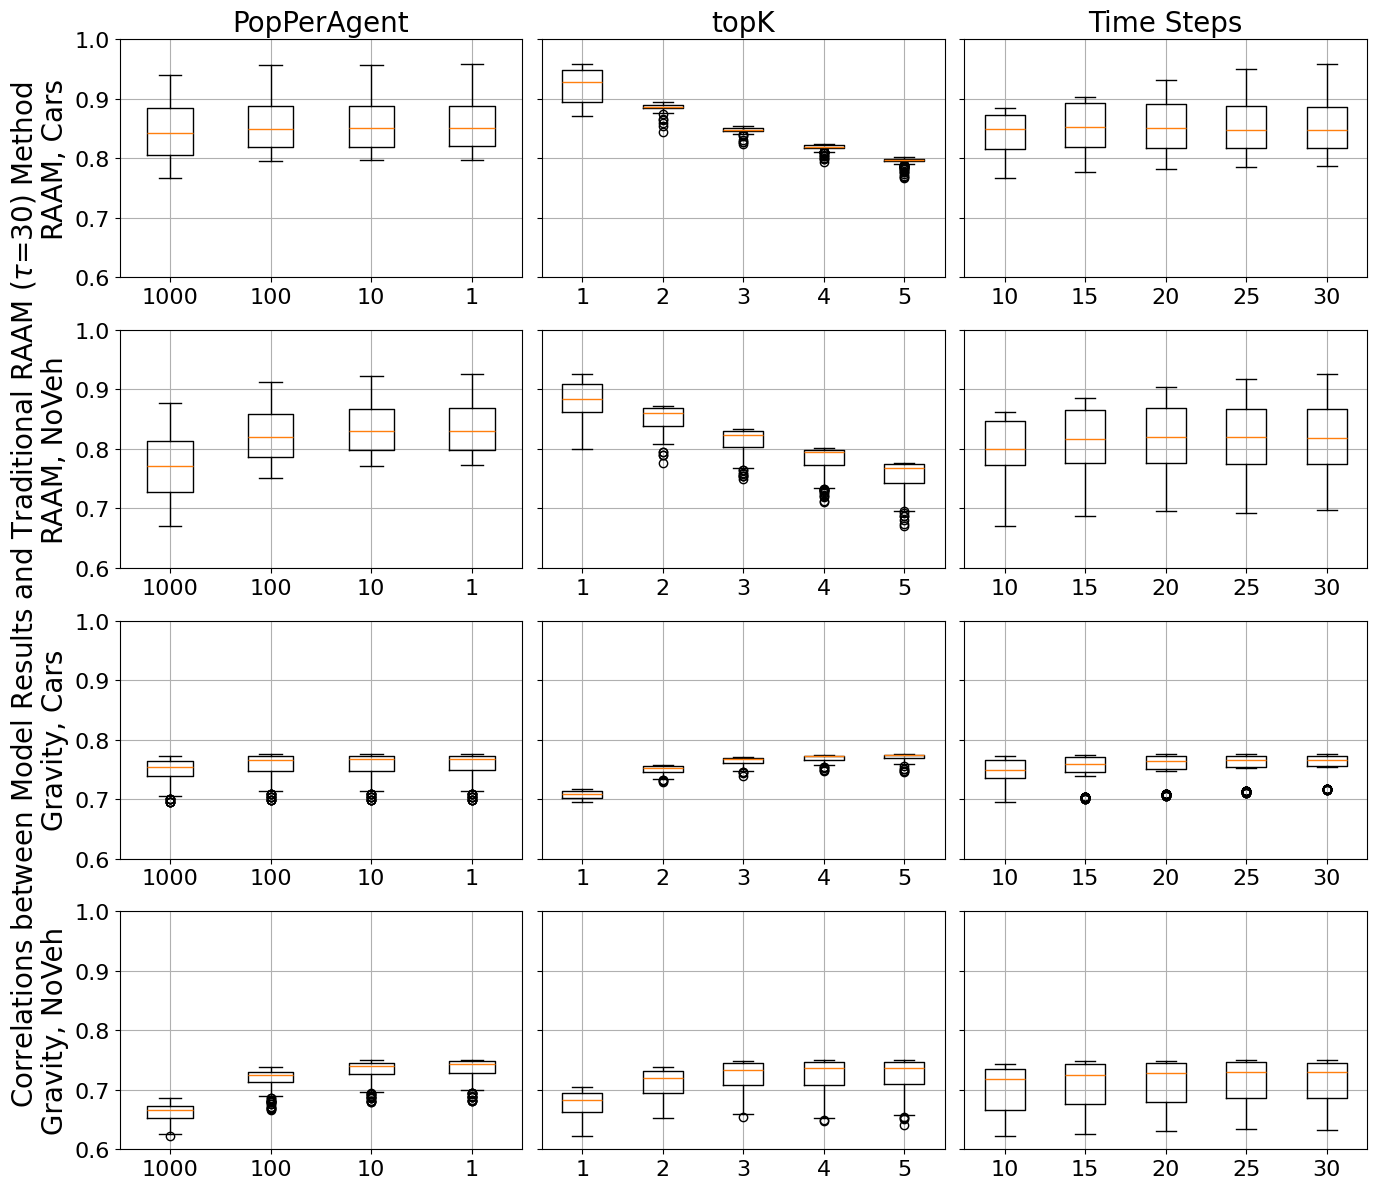

In [14]:
# for acc_col in cols:
# for acc_col in ['raam60_BEDS']:
#     print(acc_col)
#     experiment_corr = calculate_corrs(acc_col, res_col)
parameter_boxplots(experiment_corr,f"../figs/CorrelationsByParameter{acc_corr}.png")

## Mapping Results using "RAAM" Cost Function

For a completely fair comparison, we will also ignore the "NoVeh" results. We will start by creating a copy of our spatial accessibility outputs and then collecting the results for each spatial unit and model run:

In [15]:
cost_dict = {x: [] for x in acc.index}
for path in experiment_paths["onlycars"]:
    # load the parameter json
    param_path = os.path.join(path, "parameters.json")
    param_file = open(param_path)
    params = json.load(param_file)
    cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
    if cf == "raam":
        # load the data
        results = pd.read_csv(os.path.join(path, "spatial_units.csv"), index_col="GEOID")
        results.index = results.index.map(str)
        for index, row in results.iterrows():
            try:
                cost_dict[index].append(row[res_col])
            except:
                cost_dict[index] = []
                cost_dict[index].append(row[res_col])

In [16]:
# cost_dict

In [17]:
avg_costs = {key: np.mean(val) for key, val in cost_dict.items()}  # calculate mean by spatial unit

In [18]:
avg_cost_df = pd.DataFrame.from_dict(avg_costs, orient='index', columns=['AgentAccess'])
avg_cost_df.head()

,AgentAccess
17031010100,1.390497
17031010201,1.345723
17031010202,1.415129
17031010300,1.438712
17031010400,1.456525


Join our AccessAccess average cost dictionary to a copy of our accessibility outputs dataframe:

In [19]:
merged = acc.copy(deep=True).merge(avg_cost_df, left_index=True, right_index=True)
merged.head()

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry,AgentAccess
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019...",1.390497
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019...",1.345723
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012...",1.415129
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.6634 42.0150...",1.438712
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009...",1.456525


We can now calculate a correlation matrix between our average model outputs and other spatial accessibility methods:

<Axes: >

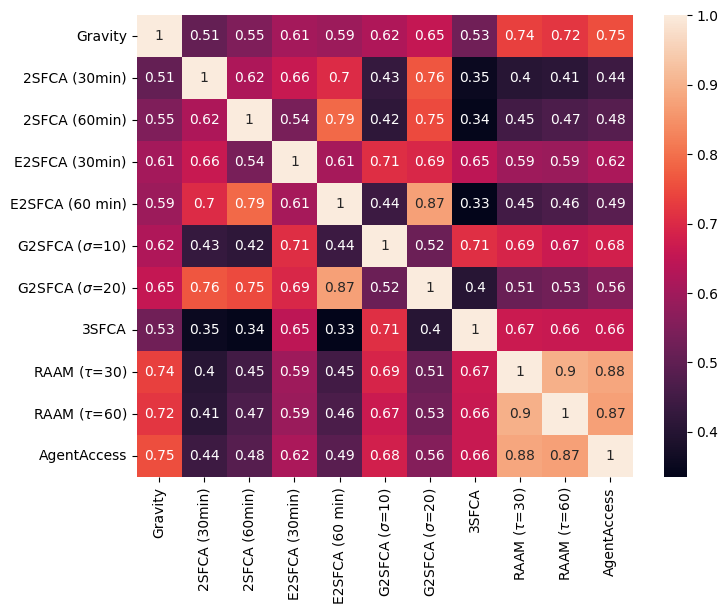

In [20]:
tmp = merged.drop(columns=["geometry"])
to_negate = ['raam30_BEDS', 'raam60_BEDS', 'AgentAccess']
for col in to_negate:
    tmp[col] = - tmp[col]
tmp = tmp.rename(columns=acc_titles)
corr = tmp.corr(method='kendall')
fig, ax = plt.subplots(figsize=(8, 6))  
sns.heatmap(corr, annot=True, ax=ax)

Let's plot the distribution of average costs using boxplots:

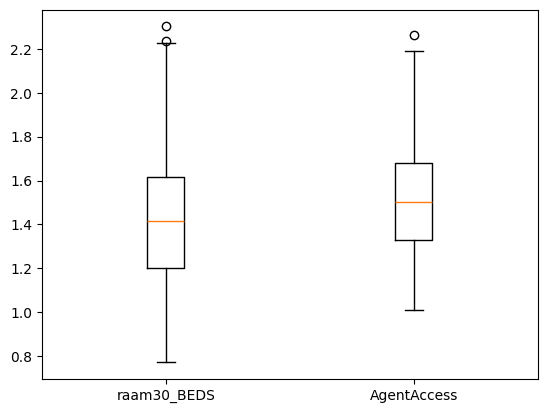

In [21]:
plt.boxplot([merged[acc_corr], merged["AgentAccess"]], tick_labels=[acc_corr, "AgentAccess"])
plt.show()

We can also map the same data:

<Axes: >

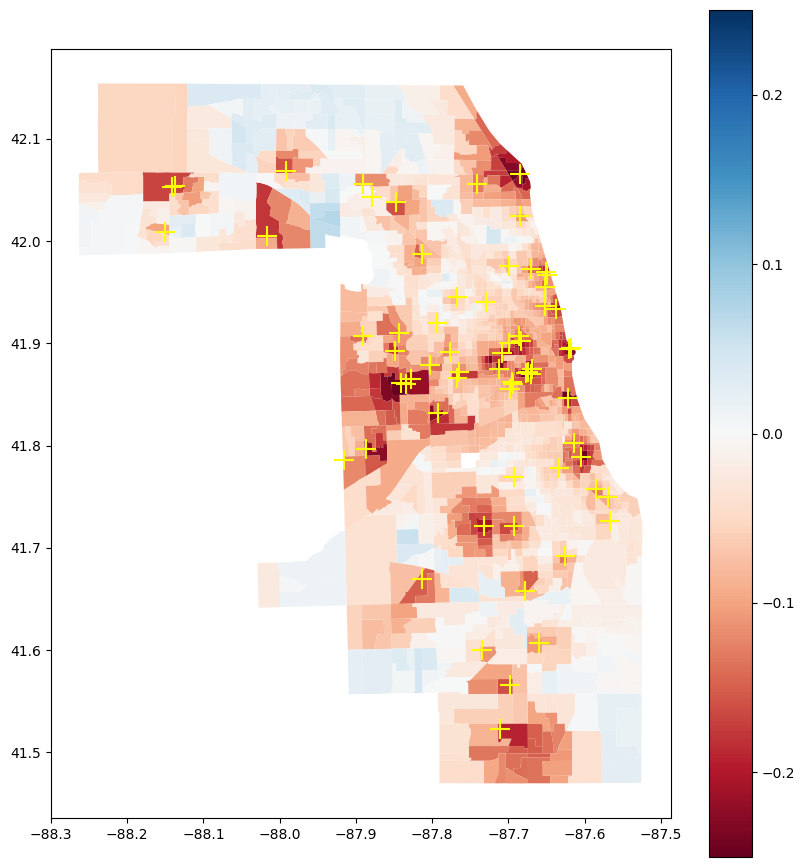

In [22]:
merged["diff"] = (merged[acc_corr] - merged['AgentAccess']) / ((merged[acc_corr] + merged['AgentAccess']) / 2.0)
ax = merged.plot(column='diff', figsize=(10, 11), legend=True, cmap="RdBu", vmin=-.25, vmax=.25)
hos.plot(ax=ax, color='yellow', marker='+', markersize=200)
# merged.head()

# Mean costs by top k

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry
geoid,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019..."
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019..."
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012..."
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.6634 42.0150..."
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009..."


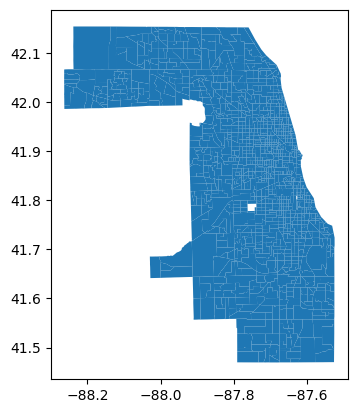

In [23]:
mean_costs_byk = acc.copy(deep=True)
mean_costs_byk.plot()
mean_costs_byk.head()

In [24]:
cost_dict = {x: dict() for x in acc.index}
for path in experiment_paths["onlycars"]:
    # load the parameter json
    param_path = os.path.join(path, "parameters.json")
    param_file = open(param_path)
    params = json.load(param_file)
    cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
    if cf == "raam":
        # load the data
        results = pd.read_csv(os.path.join(path, "spatial_units.csv"), index_col="GEOID")
        results.index = results.index.map(str)
        for index, row in results.iterrows():
            try:
                cost_dict[index][tk].append(row[res_col])
            except:
                try:
                    cost_dict[index][tk] = []
                except:
                    cost_dict[index] = dict()
                    cost_dict[index][tk] = []
                cost_dict[index][tk].append(row[res_col])
                    

In [25]:
list(cost_dict.items())[:5]  # get a preview

[('17031010100',
  {5: [np.float64(1.4851377217010793),
    np.float64(1.4827568438974386),
    np.float64(1.5205546019126053),
    np.float64(1.485374310164911),
    np.float64(1.498972321623795),
    np.float64(1.485285336052596),
    np.float64(1.4816411061251649),
    np.float64(1.4689864272226565),
    np.float64(1.4580405777958818),
    np.float64(1.4632395190892966),
    np.float64(1.4837788094088455),
    np.float64(1.4829310589438296),
    np.float64(1.4747156431650226),
    np.float64(1.4741546284675269),
    np.float64(1.4845800181098443),
    np.float64(1.485602930149992),
    np.float64(1.4886350163735371),
    np.float64(1.4718542251423312),
    np.float64(1.494178479536568),
    np.float64(1.4890032033271896),
    np.float64(1.5114604858634395),
    np.float64(1.4819148611663615),
    np.float64(1.4975603497207342),
    np.float64(1.4846594376741105),
    np.float64(1.5226502640260189),
    np.float64(1.436932280553599),
    np.float64(1.488592632717906),
    np.float64(

In [26]:
# list comprehensions can become very dumb
# for each spatial unit (key) we want average the list of results (val) indexed by the topK value (i)
avg_costs_byk = {key: [np.mean(val[i]) for i in topK] for key, val in cost_dict.items()}

In [27]:
list(avg_costs_byk.items())[:5]  # get a preview

[('17031010100',
  [np.float64(1.28996935354031),
   np.float64(1.3222536200940609),
   np.float64(1.4081267317608457),
   np.float64(1.445861128214307),
   np.float64(1.4862738579148331)]),
 ('17031010201',
  [np.float64(1.2282706139668638),
   np.float64(1.2978354254119067),
   np.float64(1.369194233202285),
   np.float64(1.4034446522627086),
   np.float64(1.4298678180131796)]),
 ('17031010202',
  [np.float64(1.324870253031166),
   np.float64(1.3725268776766446),
   np.float64(1.4355141741735098),
   np.float64(1.4582314589785446),
   np.float64(1.4845021225872055)]),
 ('17031010300',
  [np.float64(1.369090034264658),
   np.float64(1.401832835330386),
   np.float64(1.4469650992958714),
   np.float64(1.4717538232007734),
   np.float64(1.5039186274581642)]),
 ('17031010400',
  [np.float64(1.3659836987739054),
   np.float64(1.4576495473278661),
   np.float64(1.481787668458921),
   np.float64(1.48168727668801),
   np.float64(1.4955154297450708)])]

In [28]:
avg_cost_byk_df = pd.DataFrame.from_dict(avg_costs_byk, orient='index', columns=[f'topK={k}' for k in topK])
avg_cost_byk_df.head()

,topK=1,topK=2,topK=3,topK=4,topK=5
17031010100,1.289969,1.322254,1.408127,1.445861,1.486274
17031010201,1.228271,1.297835,1.369194,1.403445,1.429868
17031010202,1.324870,1.372527,1.435514,1.458231,1.484502
17031010300,1.369090,1.401833,1.446965,1.471754,1.503919
17031010400,1.365984,1.457650,1.481788,1.481687,1.495515


In [29]:
merged_byk = acc.merge(avg_cost_byk_df, left_index=True, right_index=True)
merged_byk.head()

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry,topK=1,topK=2,topK=3,topK=4,topK=5
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.66507 42.01926, -87.66604 42.019...",1.289969,1.322254,1.408127,1.445861,1.486274
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68281 42.01947, -87.68163 42.019...",1.228271,1.297835,1.369194,1.403445,1.429868
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67464 42.01263, -87.67547 42.012...",1.324870,1.372527,1.435514,1.458231,1.484502
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.66383 42.01612, -87.6634 42.0150...",1.369090,1.401833,1.446965,1.471754,1.503919
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66156 42.01041, -87.66108 42.009...",1.365984,1.457650,1.481788,1.481687,1.495515


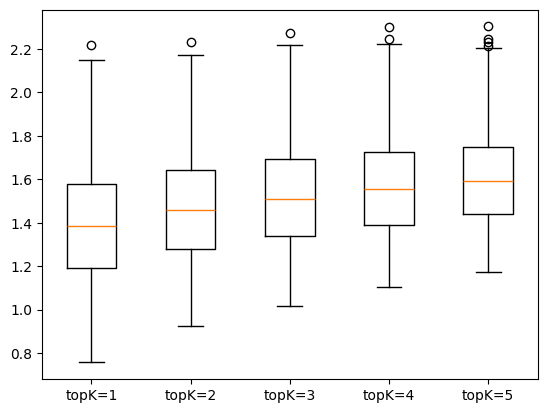

In [30]:
data, labels = [], []
for k in topK:
    data.append(merged_byk[f'topK={k}'])
    labels.append(f'topK={k}')
plt.boxplot(data, tick_labels=labels)
plt.show()

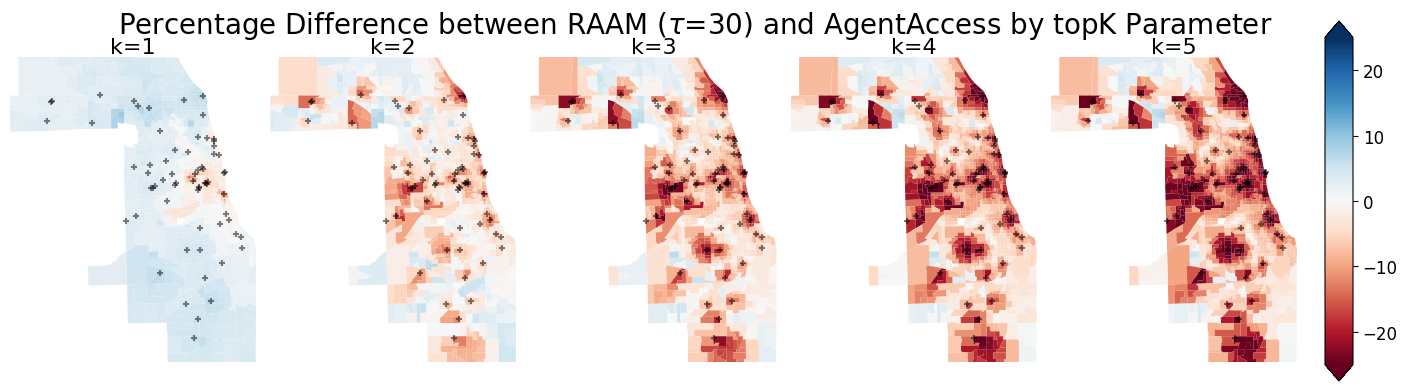

In [31]:
fontsize = 16
mycmap="RdBu"
hosmarkersize = 25
vmin, vmax = -25, 25

fig, axes = plt.subplots(1, 5, figsize=(14, 4))
fig.subplots_adjust(wspace=0, hspace=.1)

for ind, (k, ax) in enumerate(zip(topK, axes.flatten())):
    merged_byk[f"diff_{k}"] = 100 *(merged_byk[acc_corr] - merged_byk[f'topK={k}']) / ((merged_byk[acc_corr] + merged_byk[f'topK={k}']) / 2.0)
    ax.set_title(f"k={k}", fontsize=fontsize, pad=0)
    merged_byk.plot(ax=ax, column=f"diff_{k}", cmap=mycmap, vmin=vmin, vmax=vmax)
    ax.axis('off')
    ax.margins(0)
    hos.plot(ax=ax, alpha=.5, color='black', marker='+', markersize=hosmarkersize)
plt.tight_layout()


normalizer = Normalize(vmin, vmax)
im = cm.ScalarMappable(cmap=mycmap, norm=normalizer)
fig.subplots_adjust(right=0.93)
# recttuple (left, bottom, width, height)
cbar_ax = fig.add_axes([0.95, 0.05, 0.02, 0.9])

cbar_ax.tick_params(labelsize=fontsize-4)
fig.colorbar(im, cax=cbar_ax, extend='both')

fig.subplots_adjust(top=0.92)
fig.suptitle(f"Percentage Difference between {acc_titles[acc_corr]} and AgentAccess by topK Parameter", fontsize=fontsize+4)

# plt.tight_layout()
plt.savefig(f"../figs/ComparisonByTopK-{acc_corr}.png", dpi=400, bbox_inches='tight', pad_inches=0)
plt.show()